# Who were the best midfielders and forwards in the NWSL in 2023, and why?

**Question.** Which NWSL midfielders and forwards produced the most value in the 2023 season, and which on-ball actions (passes, carries, shots, tackles, fouls) explain why they stand out?

**Data.** [StatsBomb Open Data](https://github.com/statsbomb/open-data) for the complete 2023 NWSL season: all 137 matches (regular season and playoffs) and about 460,000 on-ball events. Each event has a location, the player, and its outcome. Shots carry StatsBomb's expected goals (xG) value.

**Approach.**
1. Build per-90 rates for every player with at least 900 minutes, grouped by their primary position.
2. Fit an **expected threat (xT)** model from the season's events to value every pass and carry by how much it raises the chance of scoring.
3. Rank forwards and midfielders with a transparent, role-specific composite score.
4. Explain the rankings by showing which actions separate the top 10 from everyone else.

*Key terms:* **xG** (expected goals) is the probability that a shot becomes a goal. **xA** (expected assists) is the xG of the shot a pass set up. **npxG** is non-penalty xG. **xT** (expected threat) is the change in scoring probability from moving the ball between zones. All rates are **per 90 minutes**.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from mplsoccer import Pitch, VerticalPitch, PyPizza

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import metrics as M
import plotting as P

P.set_style()
FIG_DIR = ROOT / 'figures' / '2023'
FIG_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option('display.max_columns', 40)
pd.set_option('display.precision', 2)

## 1. Load the data
`src/load_data.py` downloads the StatsBomb JSON and flattens it into three tables. Run it once before this notebook.

In [2]:
processed = ROOT / 'data' / 'processed'
if not (processed / 'events.parquet').exists():
    raise FileNotFoundError('Run `python src/load_data.py` first.')

matches = pd.read_parquet(processed / 'matches.parquet')
events = pd.read_parquet(processed / 'events.parquet')
minutes = pd.read_parquet(processed / 'player_minutes.parquet')

print(f'{len(matches)} matches, {matches.match_date.min()} to {matches.match_date.max()}')
print(f'{len(events):,} events')
events['type_name'].value_counts().head(15).to_frame('count')

137 matches, 2023-03-25 to 2023-11-12
462,436 events


,count
type_name,
Pass,123354
Ball Receipt*,117634
Carry,97060
Pressure,50360
Ball Recovery,16100
Duel,8845
Clearance,6439
Block,6079
Miscontrol,4413


## 2. Expected threat (xT): valuing passes and carries
Goals and assists are rare, and xG only credits the shooter, so they miss most of what a midfielder does. Expected threat splits the pitch into a 16 × 12 grid and asks one question per zone: *if my team has the ball here, how likely is a goal in the next few actions?* It is solved iteratively from this season's own shots, goals and successful moves ([Karun Singh, 2018](https://karun.in/blog/expected-threat.html)).

A pass or carry from zone A to zone B earns **xT(B) − xT(A)**. A sideways pass in midfield earns almost nothing. A ball slipped into the box earns a lot.

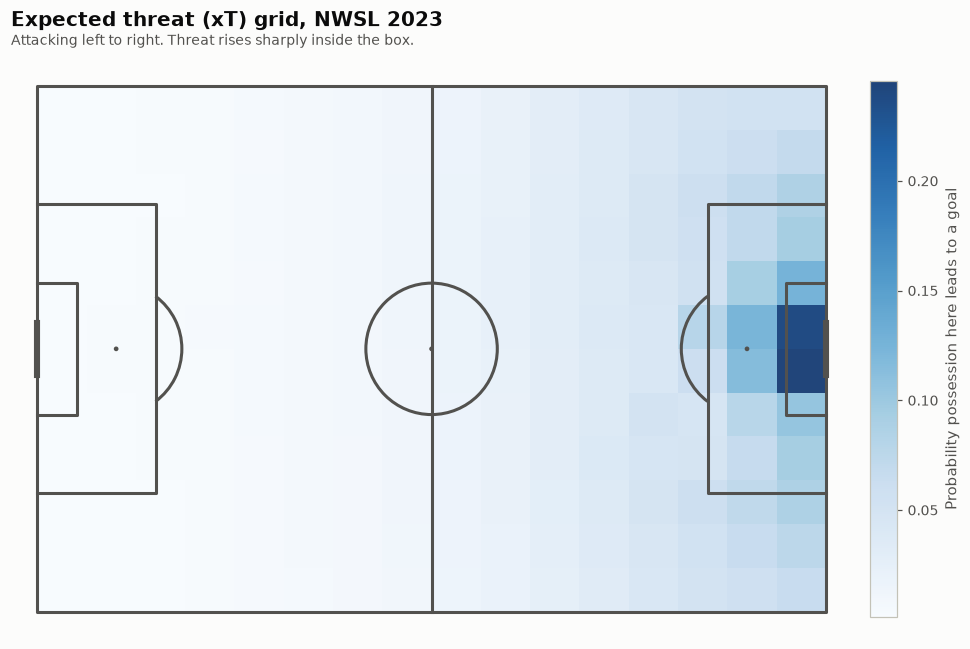

In [3]:
xt_grid = M.fit_xt(events)
events = M.add_xt(events, xt_grid)

pitch = Pitch(pitch_type='statsbomb', line_color=P.TEXT_2, line_zorder=2, pitch_color=P.SURFACE)
fig, ax = pitch.draw(figsize=(9, 6))
im = ax.imshow(xt_grid, extent=[0, 120, 80, 0], cmap='Blues', alpha=0.9, zorder=1)
cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02)
cbar.set_label('Probability possession here leads to a goal', color=P.TEXT_2)
ax.set_title('Expected threat (xT) grid, NWSL 2023', loc='left', color=P.TEXT, fontweight='bold', pad=22)
P.subtitle(ax, 'Attacking left to right. Threat rises sharply inside the box.')
fig.savefig(FIG_DIR / 'xt_grid.png')
plt.show()

## 3. Build player-season tables
Each player is assigned to the position group where they played the most minutes. Only players with **at least 900 minutes** (roughly 10 full matches) are kept, so per-90 rates aren't inflated by small samples.

In [4]:
seasons = M.player_seasons(minutes)
totals = M.player_totals(events)
players = M.per90_table(seasons, totals, min_minutes=900)
players['team_short'] = players['team'].map(P.TEAM_SHORT).fillna(players['team'])

fwd = players[players['position_group'] == 'Forward'].copy()
mid = players[players['position_group'] == 'Midfielder'].copy()
print(f'Qualified: {len(fwd)} forwards, {len(mid)} midfielders')
players.groupby('position_group')[['minutes', 'npxg_plus_xa_p90', 'xt_p90', 'progressive_passes_p90',
                                    'tackles_ints_p90', 'pressures_p90', 'fouls_committed_p90']].mean()

Qualified: 35 forwards, 44 midfielders


,minutes,npxg_plus_xa_p90,xt_p90,progressive_passes_p90,tackles_ints_p90,pressures_p90,fouls_committed_p90
position_group,,,,,,,
Defender,1722.42,7.27e-02,0.17,3.47,1.67,11.41,0.69
Forward,1432.26,3.81e-01,0.17,2.15,1.34,20.59,1.18
Goalkeeper,1698.24,1.69e-03,0.05,2.04,0.00,0.10,0.03
Midfielder,1522.87,1.89e-01,0.12,2.54,1.93,20.29,1.11


## 4. Forwards
### 4.1 Who creates the most chances, for themselves and others?
`npxG + xA per 90` measures the quality of chances a forward takes and sets up, independent of finishing luck. The dot shows actual non-penalty goals + assists per 90.

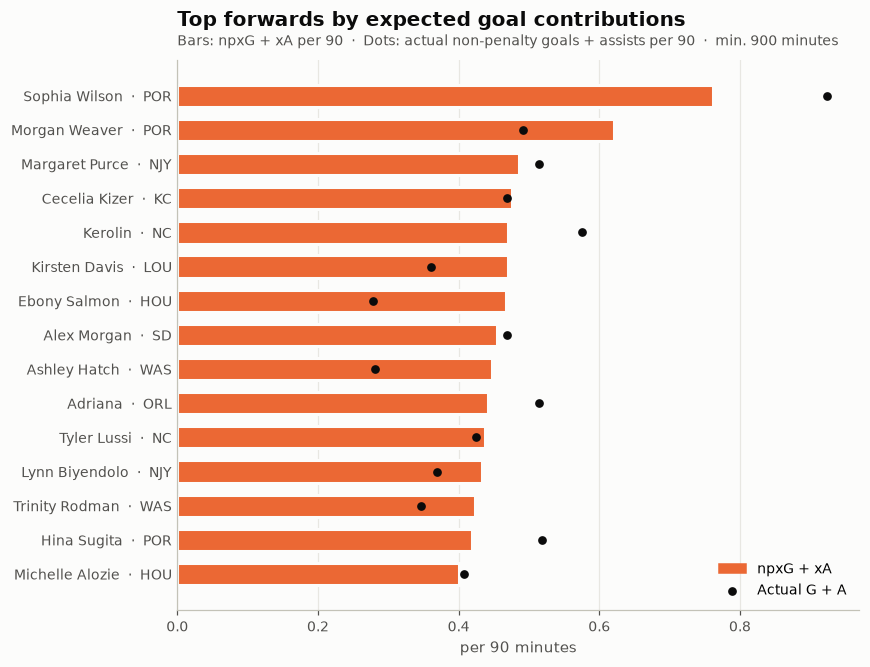

In [5]:
fig, ax = plt.subplots(figsize=(8, 6.5))
P.leaderboard(ax, fwd, 'npxg_plus_xa_p90', P.FWD, n=15, actual='g_plus_a_p90')
ax.set_xlabel('per 90 minutes')
ax.set_title('Top forwards by expected goal contributions')
P.subtitle(ax, 'Bars: npxG + xA per 90  ·  Dots: actual non-penalty goals + assists per 90  ·  min. 900 minutes')
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=P.FWD), ax.collections[-1]],
          labels=['npxG + xA', 'Actual G + A'], loc='lower right')
fig.savefig(FIG_DIR / 'forwards_leaderboard.png')
plt.show()

### 4.2 Volume or quality?
Non-penalty xG per 90 = shots per 90 × xG per shot. Forwards get there in different ways. Some shoot often from anywhere; others take fewer, better shots.

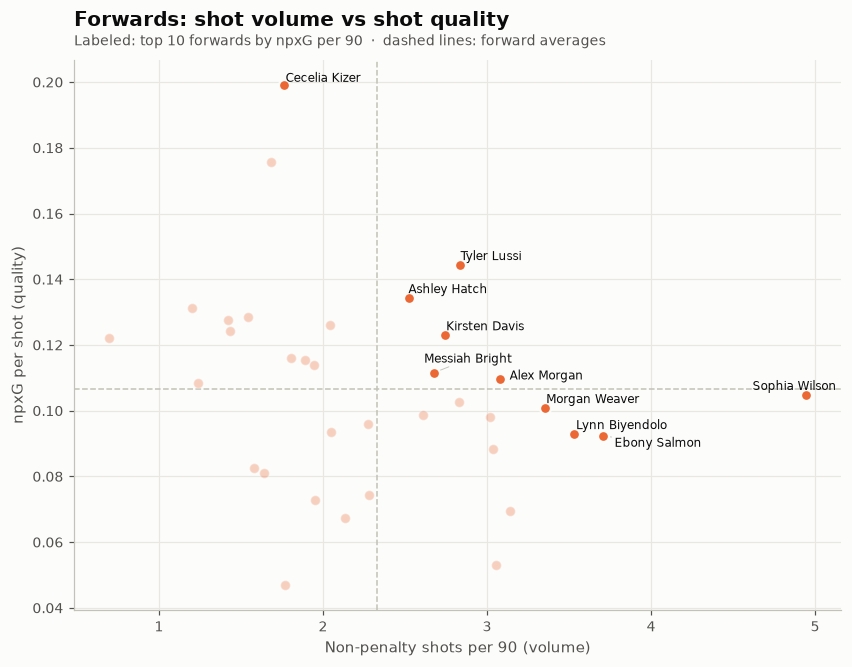

In [6]:
f = fwd.dropna(subset=['xg_per_shot'])
top_ids = f.nlargest(10, 'np_xg_p90')['player_id']
fig, ax = plt.subplots(figsize=(9, 6.5))
P.mean_lines(ax, f, 'shots_p90', 'xg_per_shot')
P.labeled_scatter(ax, f, 'shots_p90', 'xg_per_shot', f['player_id'].isin(top_ids), P.FWD)
ax.set_xlabel('Non-penalty shots per 90 (volume)')
ax.set_ylabel('npxG per shot (quality)')
ax.set_title('Forwards: shot volume vs shot quality')
P.subtitle(ax, 'Labeled: top 10 forwards by npxG per 90  ·  dashed lines: forward averages')
fig.savefig(FIG_DIR / 'forwards_volume_quality.png')
plt.show()

### 4.3 Finishing: who scored more than their chances suggested?
Points above the diagonal scored more non-penalty goals than their xG predicted. Over one season this is mostly noise plus some finishing skill, so chance creation (xG) is the more reliable signal.

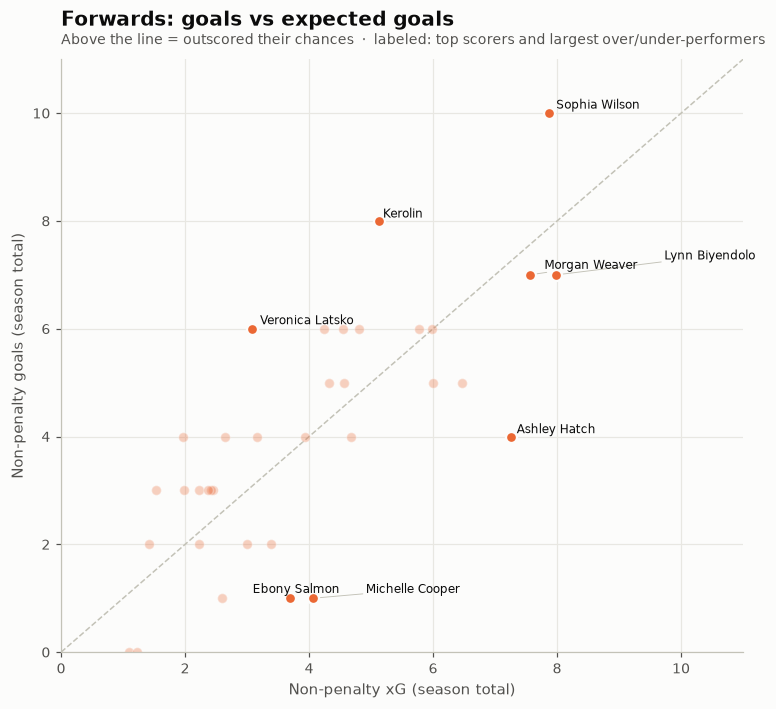

,display_name,team_short,shots,np_goals,np_xg,goals_minus_xg
28,Veronica Latsko,SEA,24.0,6.0,3.08,2.92
103,Kerolin,NC,58.0,8.0,5.12,2.88
98,Sophia Wilson,POR,75.0,10.0,7.87,2.13
144,Alyssa Thompson,LA,27.0,4.0,1.96,2.04
141,Adriana,ORL,61.0,6.0,4.24,1.76
127,Ava Cook,CHI,19.0,3.0,1.54,1.46
70,Bethany Balcer,SEA,36.0,6.0,4.54,1.46
82,Maria Morales,HOU,32.0,4.0,2.64,1.36


In [7]:
fig, ax = plt.subplots(figsize=(8, 7))
lim = max(fwd['np_xg'].max(), fwd['np_goals'].max()) + 1
ax.plot([0, lim], [0, lim], color=P.MUTED, lw=1, ls='--', zorder=1)
label = fwd['goals_minus_xg'].abs().rank(ascending=False) <= 6
label |= fwd['np_goals'].rank(ascending=False) <= 5
P.labeled_scatter(ax, fwd, 'np_xg', 'np_goals', label, P.FWD)
ax.set_xlim(0, lim); ax.set_ylim(0, lim)
ax.set_xlabel('Non-penalty xG (season total)')
ax.set_ylabel('Non-penalty goals (season total)')
ax.set_title('Forwards: goals vs expected goals')
P.subtitle(ax, 'Above the line = outscored their chances  ·  labeled: top scorers and largest over/under-performers')
fig.savefig(FIG_DIR / 'forwards_finishing.png')
plt.show()

fwd[['display_name', 'team_short', 'shots', 'np_goals', 'np_xg', 'goals_minus_xg']] \
    .sort_values('goals_minus_xg', ascending=False).head(8)

## 5. Midfielders
### 5.1 Progression vs defending: midfielder archetypes
A midfielder's job is split between moving the ball forward and winning it back. The x-axis is xT added per 90 from passes and carries. The y-axis is tackles won + interceptions per 90.

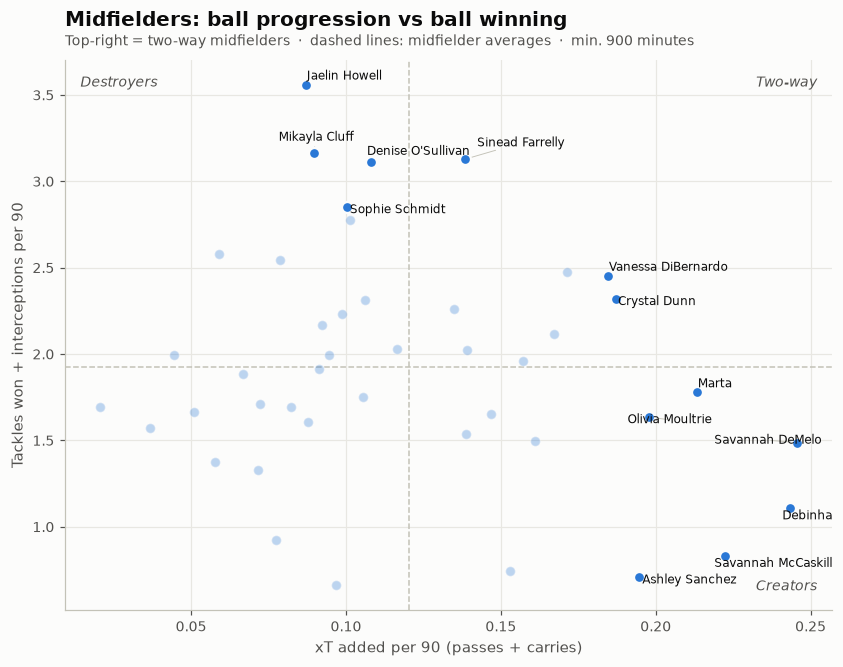

In [8]:
top_ids = mid.nlargest(8, 'xt_p90')['player_id']
top_ids = pd.concat([top_ids, mid.nlargest(5, 'tackles_ints_p90')['player_id']])
fig, ax = plt.subplots(figsize=(9, 6.5))
P.mean_lines(ax, mid, 'xt_p90', 'tackles_ints_p90')
P.labeled_scatter(ax, mid, 'xt_p90', 'tackles_ints_p90', mid['player_id'].isin(top_ids), P.MID)
ax.set_xlabel('xT added per 90 (passes + carries)')
ax.set_ylabel('Tackles won + interceptions per 90')
ax.set_title('Midfielders: ball progression vs ball winning')
P.subtitle(ax, 'Top-right = two-way midfielders  ·  dashed lines: midfielder averages  ·  min. 900 minutes')
for txt, xy in [('Creators', (0.98, 0.03)), ('Two-way', (0.98, 0.97)), ('Destroyers', (0.02, 0.97))]:
    ax.text(*xy, txt, transform=ax.transAxes, color=P.TEXT_2, fontsize=9, style='italic',
            ha='right' if xy[0] > 0.5 else 'left', va='top' if xy[1] > 0.5 else 'bottom')
fig.savefig(FIG_DIR / 'midfielders_archetypes.png')
plt.show()

### 5.2 How do they add threat: passing or carrying?

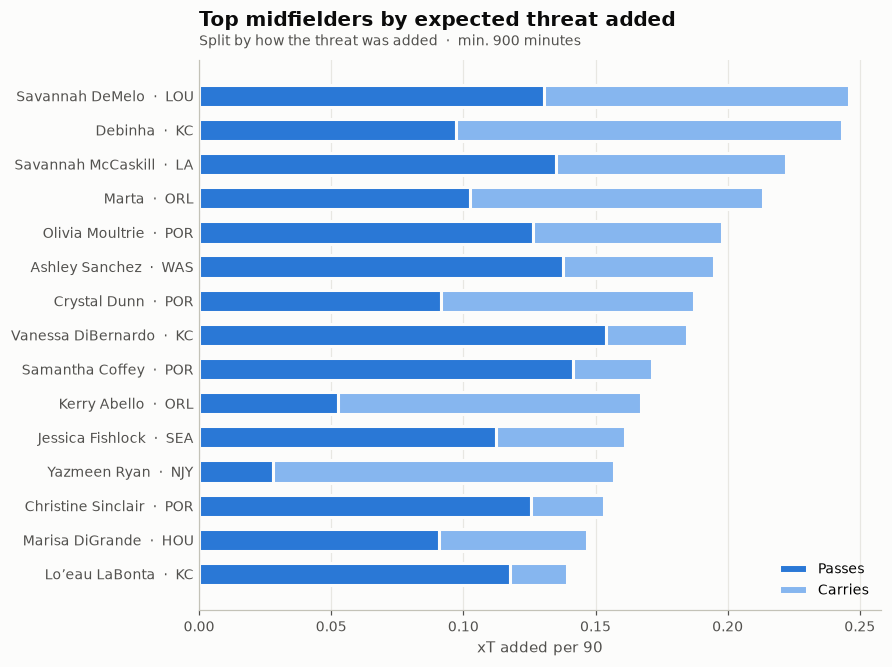

In [9]:
top = mid.nlargest(15, 'xt_p90').iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
y = np.arange(len(top))
ax.barh(y, top['xt_pass_p90'], color=P.MID, height=0.65, edgecolor=P.SURFACE, linewidth=2, label='Passes')
ax.barh(y, top['xt_carry_p90'], left=top['xt_pass_p90'], color='#86b6ef', height=0.65,
        edgecolor=P.SURFACE, linewidth=2, label='Carries')
ax.set_yticks(y, [f'{r.display_name}  ·  {r.team_short}' for r in top.itertuples()])
ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
ax.set_xlabel('xT added per 90')
ax.set_title('Top midfielders by expected threat added')
P.subtitle(ax, 'Split by how the threat was added  ·  min. 900 minutes')
ax.legend(loc='lower right')
fig.savefig(FIG_DIR / 'midfielders_xt.png')
plt.show()

## 6. A composite score for each role
No single number captures a player. I build a **role-specific composite**: each metric becomes a percentile within the position group, metrics are averaged into four categories, and the categories are weighted by how much they matter to the role. The weights are a judgment call and are written out so they can be argued with.

| Role | Category (weight) | Metrics |
|---|---|---|
| Forward | Shooting (40%) | npxG, shots, non-penalty goals |
| | Creation (30%) | xA, key passes, passes into box |
| | Carrying (20%) | xT added, progressive carries, completed dribbles |
| | Defending (10%) | pressures, tackles won + interceptions |
| Midfielder | Progression (35%) | xT added, progressive passes, progressive carries |
| | Creation (25%) | xA, key passes, passes into box |
| | Defending (25%) | tackles won + interceptions, pressures, ball recoveries |
| | Attacking output (15%) | npxG, goals + assists |

In [10]:
ROLE_CATEGORIES = {
    'Forward': {
        'Shooting':  (0.40, ['np_xg_p90', 'shots_p90', 'np_goals_p90']),
        'Creation':  (0.30, ['xa_p90', 'key_passes_p90', 'passes_into_box_p90']),
        'Carrying':  (0.20, ['xt_p90', 'progressive_carries_p90', 'dribbles_completed_p90']),
        'Defending': (0.10, ['pressures_p90', 'tackles_ints_p90']),
    },
    'Midfielder': {
        'Progression': (0.35, ['xt_p90', 'progressive_passes_p90', 'progressive_carries_p90']),
        'Creation':    (0.25, ['xa_p90', 'key_passes_p90', 'passes_into_box_p90']),
        'Defending':   (0.25, ['tackles_ints_p90', 'pressures_p90', 'ball_recoveries_p90']),
        'Attacking':   (0.15, ['np_xg_p90', 'g_plus_a_p90']),
    },
}


def composite(df, categories):
    out = df.copy()
    out['score'] = 0.0
    for cat, (weight, cols) in categories.items():
        out[cat] = out[cols].rank(pct=True).mean(axis=1) * 100
        out['score'] += weight * out[cat]
    out['rank'] = out['score'].rank(ascending=False).astype(int)
    return out.sort_values('score', ascending=False)


fwd = composite(fwd, ROLE_CATEGORIES['Forward'])
mid = composite(mid, ROLE_CATEGORIES['Midfielder'])

show = ['rank', 'display_name', 'team_short', 'primary_position', 'minutes', 'score']
print('TOP 10 FORWARDS')
display(fwd[show + list(ROLE_CATEGORIES['Forward']) + ['np_goals', 'assists', 'np_xg', 'xa']].head(10).round(1))
print('TOP 10 MIDFIELDERS')
display(mid[show + list(ROLE_CATEGORIES['Midfielder']) + ['np_goals', 'assists', 'xt_p90']].head(10).round(2))

TOP 10 FORWARDS


,rank,display_name,team_short,primary_position,minutes,score,Shooting,Creation,Carrying,Defending,np_goals,assists,np_xg,xa
98,1,Sophia Wilson,POR,Center Forward,1364.3,88.4,100.0,86.7,97.1,30.0,10.0,4.0,7.9,3.7
103,2,Kerolin,NC,Right Wing,1718.8,76.7,79.0,82.9,93.3,15.7,8.0,3.0,5.1,3.9
91,3,Morgan Weaver,POR,Left Wing,2012.1,74.0,83.8,80.0,69.5,25.7,7.0,4.0,7.6,6.3
17,4,Margaret Purce,NJY,Right Wing,1048.8,70.8,53.3,81.0,95.2,61.4,2.0,4.0,3.4,2.3
141,5,Adriana,ORL,Left Wing,1747.6,67.9,69.5,71.4,79.0,28.6,6.0,4.0,4.2,4.3
54,6,Megan Rapinoe,SEA,Left Wing,1236.8,67.8,49.5,93.3,64.8,70.0,3.0,5.0,2.2,2.9
109,7,Trinity Rodman,WAS,Right Center Forward,1819.6,62.2,65.7,44.8,86.7,51.4,5.0,2.0,6.0,2.6
1,8,Claire Emslie,LA,Right Wing,1393.6,62.1,30.5,97.1,83.8,40.0,2.0,5.0,2.2,3.7
144,9,Alyssa Thompson,LA,Left Wing,1246.3,59.2,41.9,58.1,80.0,90.0,4.0,2.0,2.0,2.7
119,10,Kirsten Davis,LOU,Center Forward,1246.0,59.0,73.3,60.0,33.3,50.0,4.0,1.0,4.7,1.8


TOP 10 MIDFIELDERS


,rank,display_name,team_short,primary_position,minutes,score,Progression,Creation,Defending,Attacking,np_goals,assists,xt_p90
43,1,Crystal Dunn,POR,Right Center Midfield,1513.98,89.51,90.91,99.24,74.24,95.45,5.0,3.0,0.19
120,2,Savannah DeMelo,LOU,Left Center Midfield,1693.72,79.83,97.73,88.64,45.45,80.68,3.0,2.0,0.25
39,3,Marta,ORL,Center Attacking Midfield,1518.12,78.47,87.88,95.45,53.79,69.32,0.0,4.0,0.21
30,4,Debinha,KC,Center Attacking Midfield,1626.45,76.84,87.88,88.64,36.36,98.86,7.0,2.0,0.24
112,5,Olivia Moultrie,POR,Right Center Midfield,1321.58,76.61,86.36,79.55,57.58,80.68,2.0,2.0,0.20
50,6,Vanessa DiBernardo,KC,Right Defensive Midfield,1027.23,70.85,80.30,58.33,83.33,48.86,0.0,1.0,0.18
47,7,Savannah McCaskill,LA,Center Attacking Midfield,2057.20,70.17,87.88,84.09,26.52,78.41,4.0,3.0,0.22
92,8,Ashley Sanchez,WAS,Center Attacking Midfield,1655.93,69.64,78.03,75.76,42.42,85.23,5.0,1.0,0.19
111,9,Yazmeen Ryan,NJY,Right Center Midfield,2020.20,69.49,81.82,57.58,69.70,60.23,2.0,1.0,0.16
143,10,Sinead Farrelly,NJY,Right Center Midfield,1006.87,69.47,70.45,71.97,84.09,38.64,0.0,1.0,0.14


### 6.1 Player profiles
Pizza charts show each of the top three players' percentile against others in their position group (100 = best). Slice colors mark the four categories.

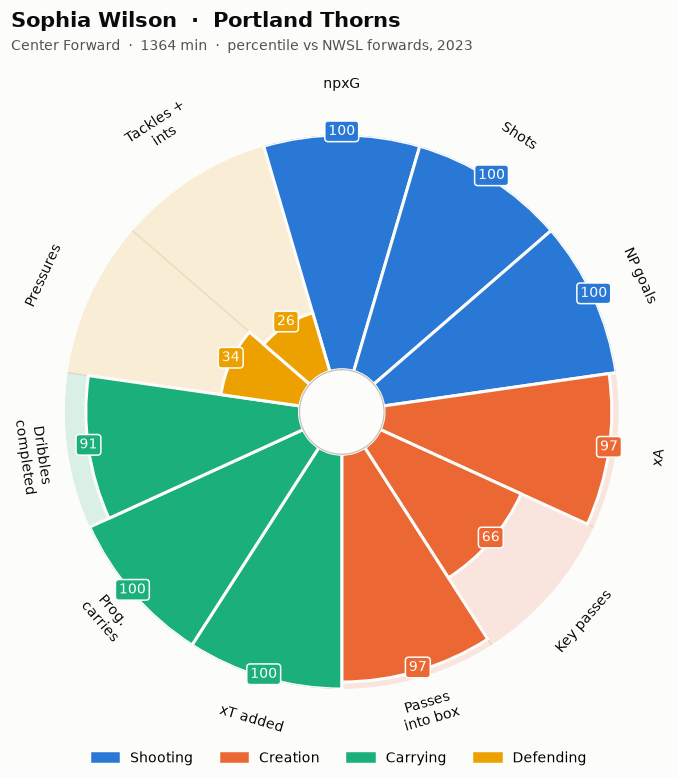

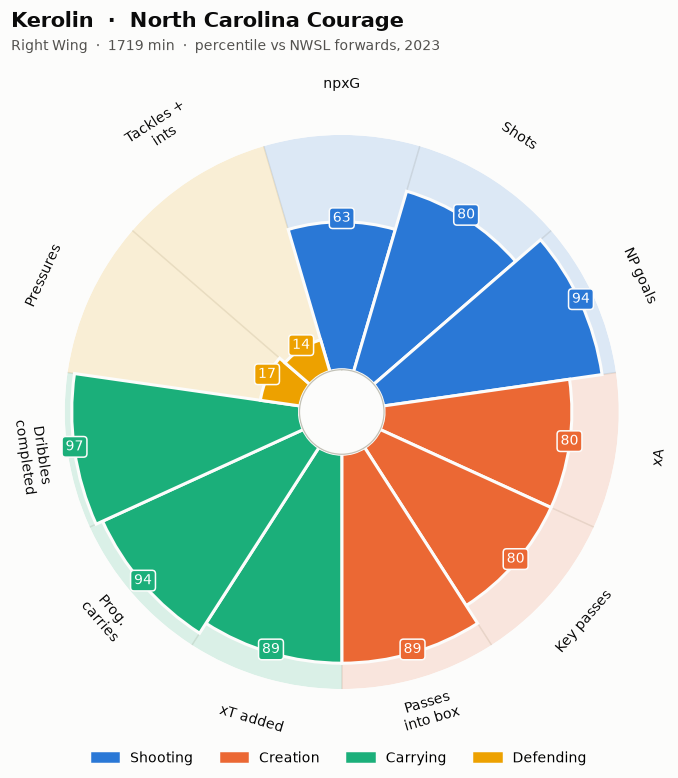

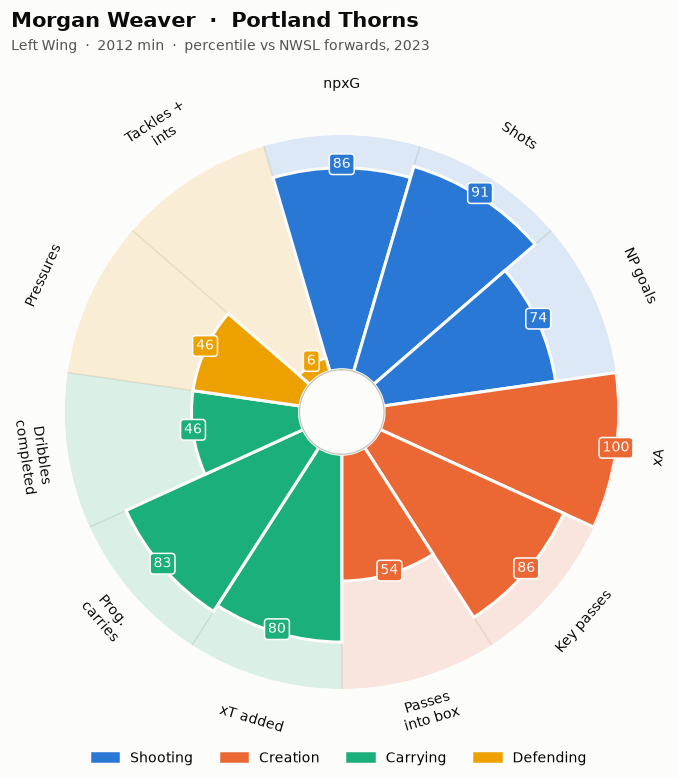

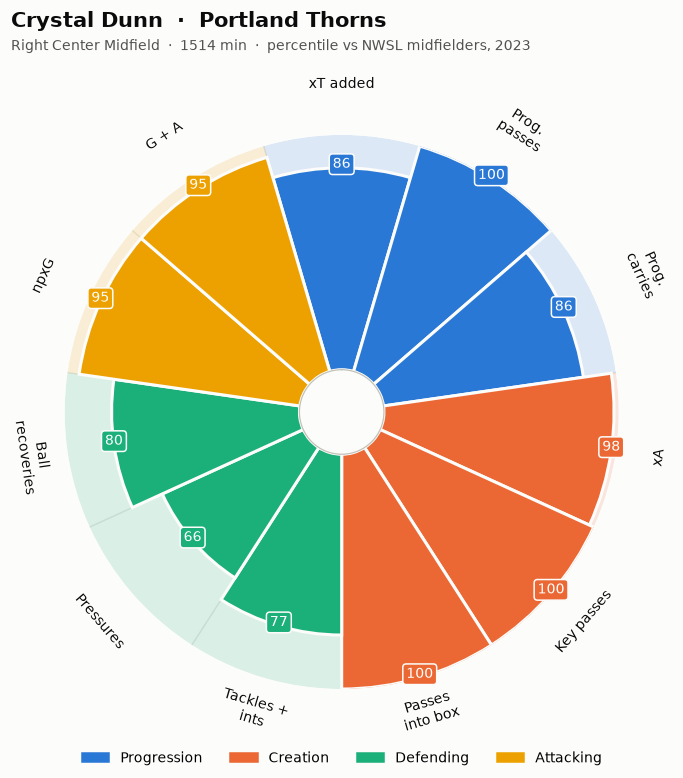

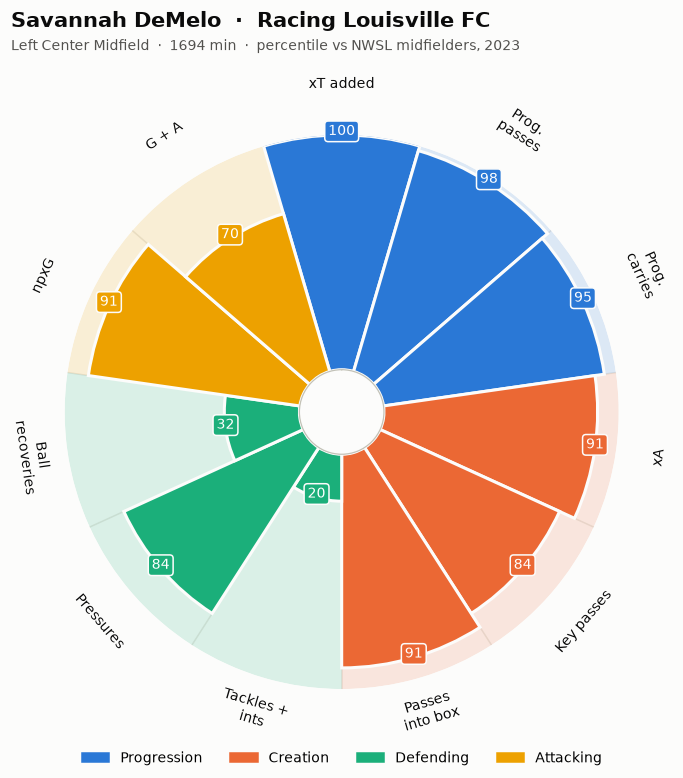

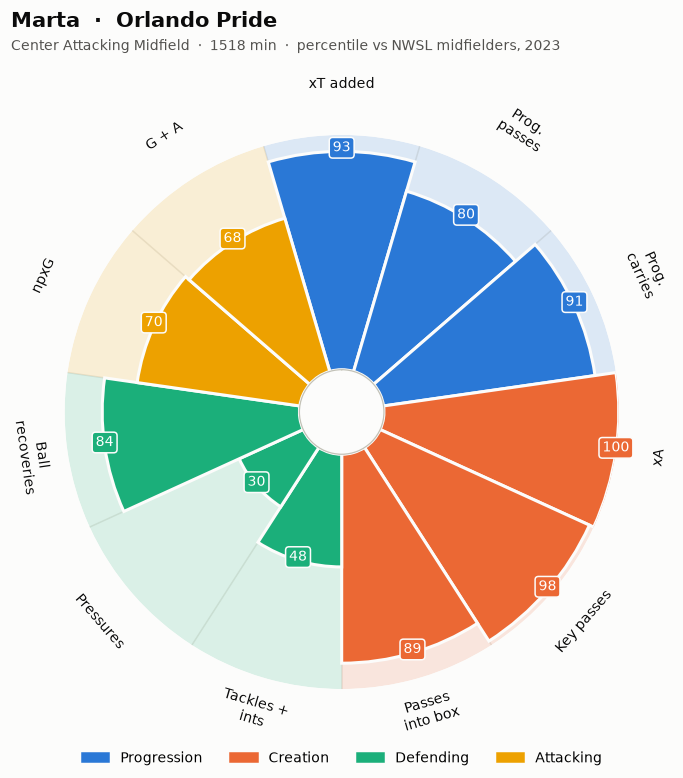

In [11]:
PIZZA_LABELS = {
    'np_xg_p90': 'npxG', 'shots_p90': 'Shots', 'np_goals_p90': 'NP goals', 'xa_p90': 'xA',
    'key_passes_p90': 'Key passes', 'passes_into_box_p90': 'Passes\ninto box', 'xt_p90': 'xT added',
    'progressive_carries_p90': 'Prog.\ncarries', 'dribbles_completed_p90': 'Dribbles\ncompleted',
    'pressures_p90': 'Pressures', 'tackles_ints_p90': 'Tackles +\nints', 'progressive_passes_p90': 'Prog.\npasses',
    'ball_recoveries_p90': 'Ball\nrecoveries', 'g_plus_a_p90': 'G + A',
}


def pizza(df, player_row, categories, fname):
    P.pizza(df, player_row, categories, PIZZA_LABELS,
            title=f"{player_row['display_name']}  ·  {player_row['team']}",
            subtitle_text=f"{player_row['primary_position']}  ·  {player_row['minutes']:.0f} min  ·  "
                          f"percentile vs NWSL {player_row['position_group'].lower()}s, 2023",
            path=FIG_DIR / fname)
    plt.show()


for _, row in fwd.head(3).iterrows():
    pizza(fwd, row, ROLE_CATEGORIES['Forward'], f"pizza_fwd_{row['rank']}.png")
for _, row in mid.head(3).iterrows():
    pizza(mid, row, ROLE_CATEGORIES['Midfielder'], f"pizza_mid_{row['rank']}.png")

### 6.2 On the pitch: the top forward's shots and the top midfielder's progressive passes

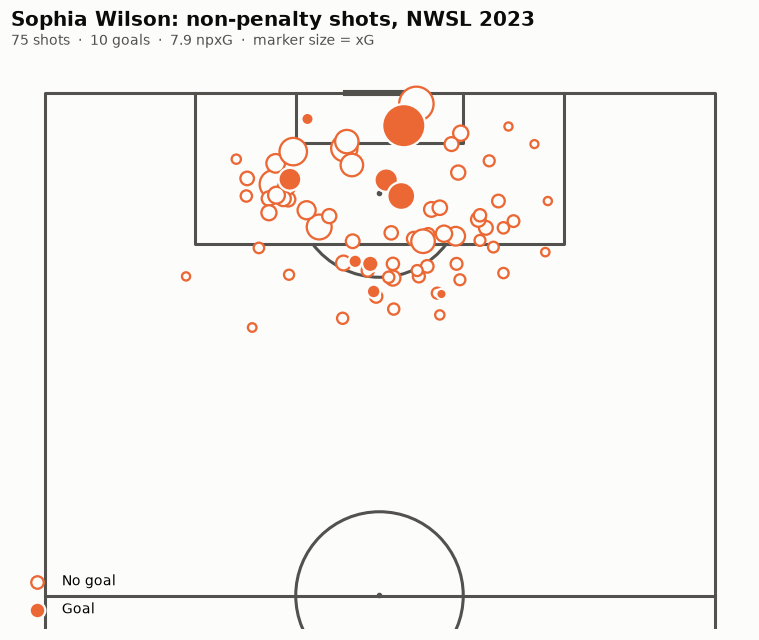

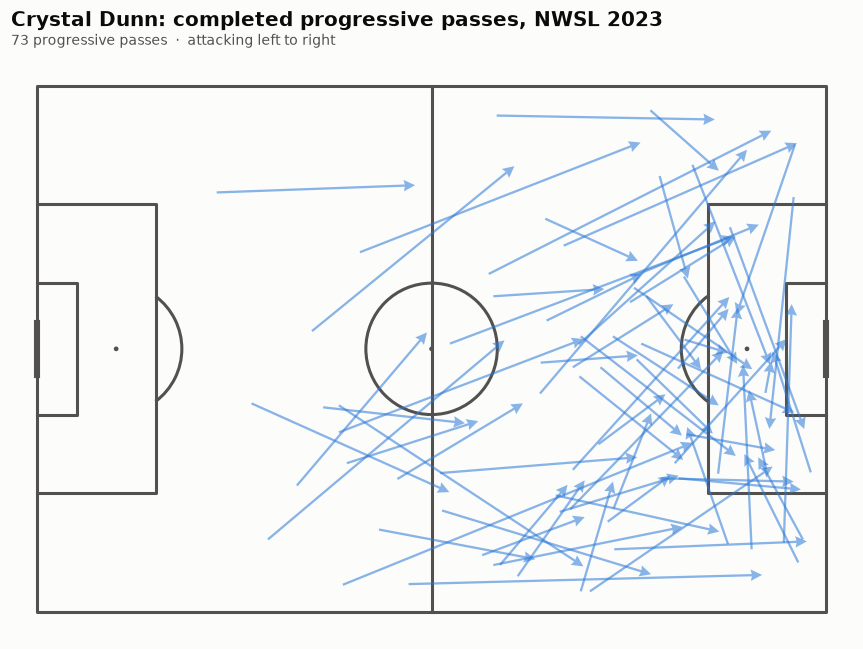

In [12]:
top_fwd = fwd.iloc[0]
top_mid = mid.iloc[0]

shots = events[(events['player_id'] == top_fwd['player_id']) & (events['type_name'] == 'Shot')
               & (events['shot_type_name'] != 'Penalty')]
is_goal = shots['shot_outcome_name'] == 'Goal'

vpitch = VerticalPitch(pitch_type='statsbomb', half=True, line_color=P.TEXT_2, pitch_color=P.SURFACE)
fig, ax = vpitch.draw(figsize=(7, 6))
vpitch.scatter(shots.loc[~is_goal, 'x'], shots.loc[~is_goal, 'y'], s=shots.loc[~is_goal, 'shot_statsbomb_xg'] * 900 + 20,
               color=P.SURFACE, edgecolors=P.FWD, linewidth=1.5, ax=ax, label='No goal', zorder=2)
vpitch.scatter(shots.loc[is_goal, 'x'], shots.loc[is_goal, 'y'], s=shots.loc[is_goal, 'shot_statsbomb_xg'] * 900 + 20,
               color=P.FWD, edgecolors=P.SURFACE, linewidth=1.5, ax=ax, label='Goal', zorder=3)
ax.set_title(f"{top_fwd['display_name']}: non-penalty shots, NWSL 2023", loc='left', fontweight='bold', color=P.TEXT, pad=22)
P.subtitle(ax, f"{len(shots)} shots  ·  {is_goal.sum()} goals  ·  {shots['shot_statsbomb_xg'].sum():.1f} npxG  ·  marker size = xG")
ax.legend(loc='lower left', fontsize=9, markerscale=0.5, labelspacing=1.0)
fig.savefig(FIG_DIR / 'shotmap_top_forward.png')
plt.show()

pm = events[(events['player_id'] == top_mid['player_id']) & (events['type_name'] == 'Pass')
            & events['pass_outcome_name'].isna()]
start_d = np.hypot(120 - pm['x'], 40 - pm['y'])
end_d = np.hypot(120 - pm['pass_end_x'], 40 - pm['pass_end_y'])
prog = pm[(end_d <= 0.75 * start_d) & (pm['pass_end_x'] >= 48) & ~pm['pass_type_name'].isin(M.SET_PIECE_PASSES)]

pitch = Pitch(pitch_type='statsbomb', line_color=P.TEXT_2, pitch_color=P.SURFACE)
fig, ax = pitch.draw(figsize=(9, 6))
pitch.arrows(prog['x'], prog['y'], prog['pass_end_x'], prog['pass_end_y'], width=1.5, headwidth=5,
             headlength=5, color=P.MID, alpha=0.55, ax=ax)
ax.set_title(f"{top_mid['display_name']}: completed progressive passes, NWSL 2023", loc='left',
             fontweight='bold', color=P.TEXT, pad=22)
P.subtitle(ax, f"{len(prog)} progressive passes  ·  attacking left to right")
fig.savefig(FIG_DIR / 'passmap_top_midfielder.png')
plt.show()

## 7. Why: what separates the best from the rest?
For each position group I compare the **top 10 by composite score** with everyone else. For each on-ball metric I compute a standardized difference: (top-10 mean − rest mean) / pooled standard deviation. A value of 1.0 means the top group is a full standard deviation better on that action. This shows which actions drive the gap.

The composite itself is built from some of these metrics, so the more interesting result is the **ordering**: which actions separate the groups most, including metrics that are *not* in the score (fouls, pass completion, turnovers).

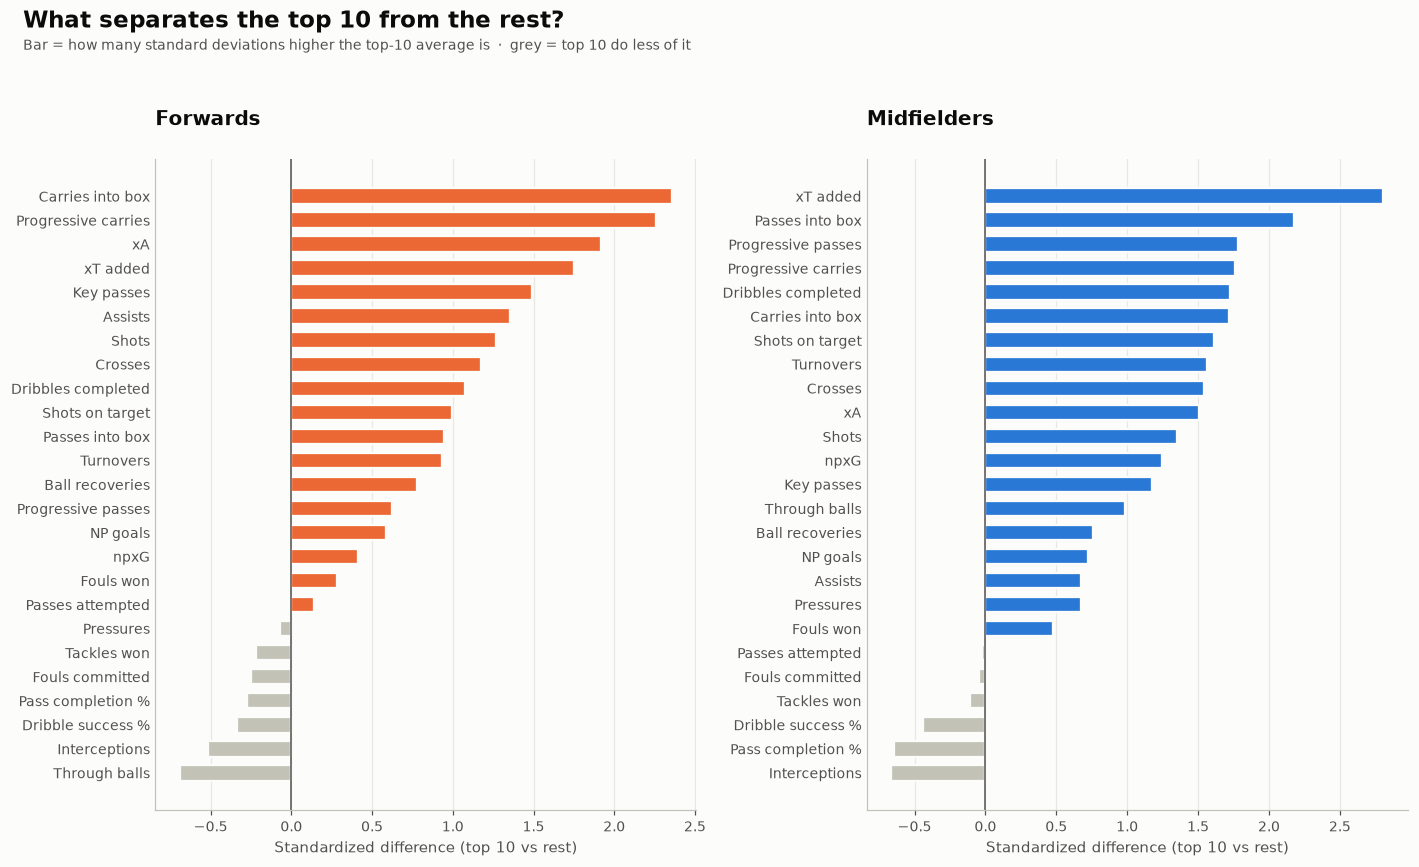

Forwards                   Midfielders                  
                       top10  rest effect_size       top10  rest effect_size
metric                                                                      
Carries into box        3.08  1.17        2.36        1.08  0.27        1.72
Progressive carries     6.04  2.53        2.26        2.53  0.88        1.76
xA                      0.21  0.11        1.92         NaN   NaN         NaN
xT added                0.26  0.13        1.75        0.20  0.10        2.81
Key passes              1.76  1.05        1.49         NaN   NaN         NaN
Assists                 0.22  0.09        1.36         NaN   NaN         NaN
Shots                   3.02  2.05        1.27         NaN   NaN         NaN
Crosses                 2.93  1.62        1.18         NaN   NaN         NaN
Passes into box          NaN   NaN         NaN        1.17  0.51        2.18
Progressive passes       NaN   NaN         NaN        3.35  2.30        1.78
Dribbles completed       NaN   NaN         NaN        1.29  0.64        1.73
Shots on target          NaN   NaN         NaN        0.71  0.30        1.61
Turnovers                NaN   NaN         NaN        4.46  2.40        1.57

In [13]:
WHY_METRICS = {
    'np_xg_p90': 'npxG', 'shots_p90': 'Shots', 'shots_on_target_p90': 'Shots on target',
    'np_goals_p90': 'NP goals', 'xa_p90': 'xA', 'assists_p90': 'Assists', 'key_passes_p90': 'Key passes',
    'passes_into_box_p90': 'Passes into box', 'through_balls_p90': 'Through balls', 'crosses_p90': 'Crosses',
    'passes_p90': 'Passes attempted', 'pass_pct': 'Pass completion %', 'progressive_passes_p90': 'Progressive passes',
    'progressive_carries_p90': 'Progressive carries', 'carries_into_box_p90': 'Carries into box',
    'xt_p90': 'xT added', 'dribbles_completed_p90': 'Dribbles completed', 'dribble_pct': 'Dribble success %',
    'tackles_won_p90': 'Tackles won', 'interceptions_p90': 'Interceptions', 'pressures_p90': 'Pressures',
    'ball_recoveries_p90': 'Ball recoveries', 'fouls_committed_p90': 'Fouls committed',
    'fouls_won_p90': 'Fouls won', 'turnovers_p90': 'Turnovers',
}


def separation(df, n_top=10):
    top = df.head(n_top)
    rest = df.iloc[n_top:]
    rows = []
    for col, label in WHY_METRICS.items():
        pooled = np.sqrt((top[col].var() + rest[col].var()) / 2)
        rows.append({'metric': label, 'col': col, 'top10': top[col].mean(), 'rest': rest[col].mean(),
                     'effect_size': (top[col].mean() - rest[col].mean()) / pooled})
    return pd.DataFrame(rows).sort_values('effect_size')


sep_fwd = separation(fwd)
sep_mid = separation(mid)

fig, axes = plt.subplots(1, 2, figsize=(13, 8), sharey=False)
for ax, sep, color, name in [(axes[0], sep_fwd, P.FWD, 'Forwards'), (axes[1], sep_mid, P.MID, 'Midfielders')]:
    y = np.arange(len(sep))
    colors = [color if v > 0 else P.MUTED for v in sep['effect_size']]
    ax.barh(y, sep['effect_size'], color=colors, height=0.65, edgecolor=P.SURFACE, linewidth=1.5)
    ax.axvline(0, color=P.TEXT_2, lw=1)
    ax.set_yticks(y, sep['metric'])
    ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
    ax.set_xlabel('Standardized difference (top 10 vs rest)')
    ax.set_title(name)
fig.suptitle('What separates the top 10 from the rest?', x=0.02, ha='left', fontsize=15, fontweight='bold', color=P.TEXT)
fig.text(0.02, 0.935, 'Bar = how many standard deviations higher the top-10 average is  ·  grey = top 10 do less of it',
         color=P.TEXT_2, fontsize=9)
fig.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig(FIG_DIR / 'why_separation.png')
plt.show()

pd.concat({'Forwards': sep_fwd.set_index('metric')[['top10', 'rest', 'effect_size']].iloc[::-1].head(8),
           'Midfielders': sep_mid.set_index('metric')[['top10', 'rest', 'effect_size']].iloc[::-1].head(8)}, axis=1)

### 7.1 Which on-ball actions go with actual goal contributions?
As a check that doesn't depend on my weights, I correlate each action rate with **actual non-penalty goals + assists per 90** across all qualified midfielders and forwards. Expected metrics (npxG, xA) are left out because they are built from the same shots and passes as the outcome.

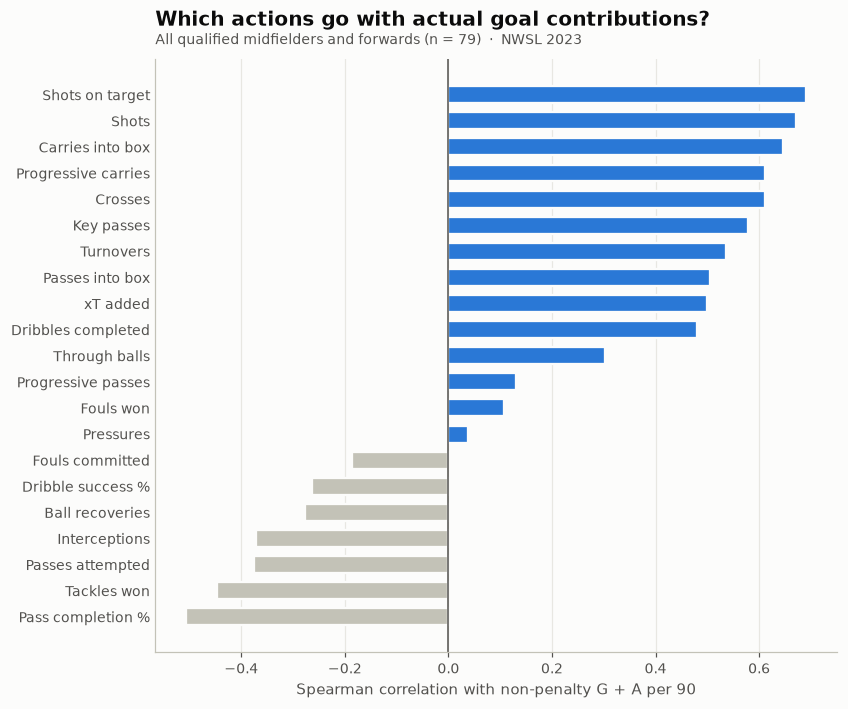

,spearman_r
Shots on target,0.69
Shots,0.67
Carries into box,0.65
Progressive carries,0.61
Crosses,0.61
Key passes,0.58
Turnovers,0.54
Passes into box,0.51
xT added,0.50
Dribbles completed,0.48


In [14]:
attackers = pd.concat([fwd, mid])
candidates = [c for c in WHY_METRICS if c not in {'np_xg_p90', 'np_goals_p90', 'xa_p90', 'assists_p90'}]
corr = attackers[candidates + ['g_plus_a_p90']].corr(method='spearman')['g_plus_a_p90'].drop('g_plus_a_p90')
corr = corr.rename(WHY_METRICS).sort_values()

fig, ax = plt.subplots(figsize=(8, 7))
y = np.arange(len(corr))
ax.barh(y, corr.values, color=[P.MID if v > 0 else P.MUTED for v in corr.values], height=0.65,
        edgecolor=P.SURFACE, linewidth=1.5)
ax.axvline(0, color=P.TEXT_2, lw=1)
ax.set_yticks(y, corr.index)
ax.grid(axis='y', visible=False); ax.tick_params(axis='y', length=0)
ax.set_xlabel('Spearman correlation with non-penalty G + A per 90')
ax.set_title('Which actions go with actual goal contributions?')
P.subtitle(ax, f'All qualified midfielders and forwards (n = {len(attackers)})  ·  NWSL 2023')
fig.savefig(FIG_DIR / 'why_correlation.png')
plt.show()
corr.sort_values(ascending=False).round(2).to_frame('spearman_r')

## 8. Findings
**Best forwards: Sophia Smith, Kerolin, Morgan Weaver.**
- **Sophia Smith** (listed in StatsBomb under her current name, Sophia Wilson) is the clear #1. She sits in the 100th percentile among forwards for npxG, shots, non-penalty goals, progressive carries and xT added. She produced 0.76 npxG + xA per 90, twice the forward average of 0.38, and scored 10 non-penalty goals with 4 assists in 1,364 minutes.
- **Kerolin** (#2) and **Morgan Weaver** (#3) follow. Weaver generated the most xA of any forward (6.3) on top of 7.6 npxG.
- **Finishing:** Veronica Latsko (+2.9), Kerolin (+2.9) and Smith (+2.1) scored the most above their xG. Over one season that is partly luck, so the rankings lean on chance creation rather than finishing.

**Best midfielders: Crystal Dunn, Savannah DeMelo, Marta.**
- **Crystal Dunn** is the most complete midfielder: 99th percentile for creation, 95th for attacking output and 74th for defending, with 5 goals and 3 assists. She is one of the few true two-way midfielders (top right of the archetype chart).
- **Savannah DeMelo** added the most expected threat per 90 of any midfielder (0.25, about 2.5× the midfield average). **Marta** had 4 assists and 4.4 xA without scoring. **Debinha** was the most direct scorer, with 7 non-penalty goals.

**Why: what separates the best from the rest?**
1. **Carrying the ball into danger.** For forwards, the biggest separators are carries into the box (3.1 vs 1.2 per 90) and progressive carries (6.0 vs 2.5). These matter more than raw npxG, so elite forwards create their own chances instead of waiting for service.
2. **Moving the ball forward, not just keeping it.** For midfielders, xT added (0.20 vs 0.10 per 90) and passes into the box separate the top 10 most strongly.
3. **Risk over safety.** Elite midfielders have *lower* pass completion and *more* turnovers. Across all attackers, pass completion % correlates negatively with goal contributions (r = −0.51). The best players attempt the harder, more valuable pass.
4. **Defensive volume doesn't separate the elite.** Pressures, tackles and fouls show almost no difference between the top 10 and the rest in either position. Tackles won correlate negatively with goal contributions (r = −0.45), which reflects role (deeper players defend more) rather than defending being bad.
5. **Getting shots on target goes with production.** Shots on target (r = 0.69), shots (0.67) and carries into the box (0.65) have the strongest relationships with actual goals + assists per 90.

*Caution: the composite score is built partly from these metrics, so the separation chart describes the top group rather than independently proving why they are best. The correlation analysis in 7.1 is the weight-free check.*

## 9. Limitations and next steps
- **One season.** 900+ minutes is still a small sample. Finishing over or under xG in particular regresses heavily from year to year.
- **Event data only.** There is no tracking data, so off-ball runs, spacing and pressing shape are invisible. Pressures are counted, not valued.
- **Team context.** Players on dominant teams (more possession, more box entries) get more chances to rack up per-90 numbers. Possession-adjusting the defensive stats is a natural next step.
- **Composite weights** are a modelling choice. An alternative is to learn weights by regressing team goal difference on players' action rates.
- **Next:** repeat for the 2018 NWSL season (also in StatsBomb open data) to see which players and profiles hold up, and build a Streamlit player-similarity app on top of these per-90 tables.